# Extreme Weather Reports in a Warming World
### Reporting trends, seasonality, SST associations and reported damage, 1996–2024

This project uses NOAA Storm Events records and ERSSTv5 to examine three questions:

1. How do annual **reported record counts** vary over the study period, and how sensitive is the pattern to the counting unit?
2. How does the distribution of **record start months** differ between 1996–2010 and 2011–2024?
3. Does annual regional SST covary with reported counts after a shared linear time trend is removed?

Reported property and crop damage provides a separate descriptive analysis. All storm results cover the **48 contiguous US states and Washington, DC**, using county and forecast-zone records. Offshore marine areas, Alaska, Hawaii and territories are excluded. This geographical scope is narrower than the original notebook's all-location totals.

**This is an exploratory observational analysis.** A database record is not necessarily an independent physical storm. Reporting practices, hazard definitions, population and exposure can change. The analysis does not estimate a causal effect of warming, correct reporting bias, or estimate total economic loss.

This revision retains the original study period and data sources while correcting the counting language, seasonal inference, time-series analysis and damage comparisons. Reusable calculations are in `weather_analysis.py`; this notebook explains and displays them.

## 1. Reproducibility and data audit

Install `requirements.txt` in a Python 3.12 environment, then run this notebook from the repository directory. The first run downloads approximately 453 MB of raw inputs; subsequent runs verify and reuse the cache. `data_manifest.json` records exact NOAA revisions, retrieval times and SHA-256 hashes. NOAA's SST download is mutable: a different file causes an explicit checksum error rather than silently changing the results. See the README for updating it.

`EVENT_ID` is retained as the record identifier, while `EPISODE_ID` is kept for auditing. Exact duplicate rows are removed; conflicting rows with the same event ID stop the run. Start dates determine year and month. Source `YEAR` disagreements are exported for inspection, not silently corrected. Missing or invalid damage strings remain missing; explicit zeros remain zero.

Heat and drought are separate groups. Tornado excludes funnel clouds and waterspouts, which remain in Other. Flood / Rain includes heavy rain; Tropical / Surge includes storm surge. Every observed type and its assigned group is exported to `results/event_type_mapping.csv`.

In [1]:
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from weather_analysis import run_analysis, make_figures, CATEGORIES, YEARS, detrend

result = run_analysis()
annual = result['annual']
pd.options.display.float_format = '{:,.3f}'.format
display(pd.Series(result['quality'], name='Count').to_frame())
display(result['date_audit'])

Analyzed 1,627,967 CONUS records over 29 years.


,Count
raw_rows,1708370
exact_duplicates_removed,0
conus_records,1627967
excluded_geography_rows,80403
missing_episode_ids,3
source_year_differs_from_start_year,8
invalid_property_strings,44
missing_property_values,569258
invalid_crop_strings,5
missing_crop_values,680820


,EVENT_ID,STATE,EVENT_TYPE,YEAR,date,BEGIN_DATE_TIME,END_DATE_TIME
64893,5585757,WASHINGTON,Ice Storm,1997,1996-01-17,17-JAN-96 17:00:00,16-JAN-97 12:00:00
65554,5585735,WASHINGTON,Flood,1997,1996-01-09,09-JAN-96 12:00:00,01-JAN-97 00:00:00
65555,5585736,WASHINGTON,Flood,1997,1996-01-09,09-JAN-96 12:00:00,01-JAN-97 00:00:00
65556,5585737,WASHINGTON,Flood,1997,1996-01-09,09-JAN-96 12:00:00,01-JAN-97 00:00:00
65557,5585738,WASHINGTON,Flood,1997,1996-01-09,09-JAN-96 12:00:00,01-JAN-97 00:00:00
65558,5585739,WASHINGTON,Flood,1997,1996-01-09,09-JAN-96 12:00:00,01-JAN-97 00:00:00
74624,5586839,MARYLAND,Winter Weather,1997,1996-01-24,24-JAN-96 19:00:00,24-JAN-97 12:00:00
74625,5586840,MARYLAND,Winter Weather,1997,1996-01-24,24-JAN-96 19:00:00,24-JAN-97 12:00:00


The source-year disagreements shown above are retained according to their recorded start dates. They may reflect unusual durations or source errors; this analysis does not invent replacement dates. Geographic exclusions and missing damage counts are explicit in the audit. See `results/largest_damage_records.csv` for the records most influential in the loss totals.

In [2]:
plt.ioff()
figures = make_figures(result)
for figure in figures:
    plt.close(figure)
display(result['event_type_mapping'])

,EVENT_TYPE,category,records
0,Astronomical Low Tide,Other,653
1,Avalanche,Other,744
2,Blizzard,Winter / Cold,14544
3,Coastal Flood,Flood / Rain,4135
4,Cold/Wind Chill,Winter / Cold,16790
5,Debris Flow,Other,1755
6,Dense Fog,Other,16794
7,Dense Smoke,Other,145
8,Drought,Drought,76277
9,Dust Devil,Other,240


## 2. SST context

ERSSTv5 monthly temperatures are expressed as anomalies from the **1991–2020 calendar-month climatology**. The regional series averages valid ocean grid cells within **20–50°N, 130–60°W**, using cosine-latitude area weights. Annual means then weight months by their number of days. All 408 months in 1991–2024 must be present before calculating the climatology and study series.

The rectangle below shows the selected box. It combines parts of the Pacific and Atlantic and is a broad regional index, not a validated physical predictor for every hazard. The map compares two decadal means and does not show statistical significance or attribution. Those decadal map means weight each month equally; annual regional indices use day weights.

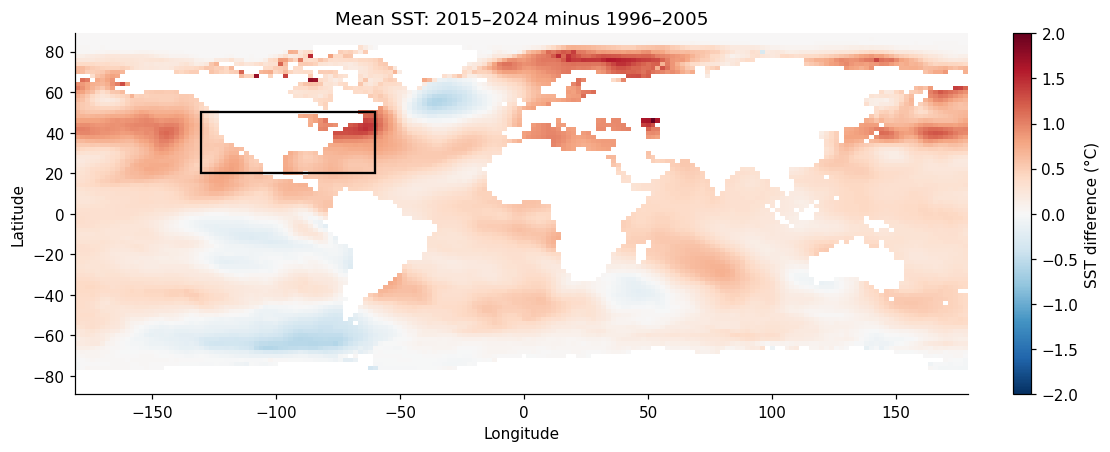

In [3]:
display(figures[0])

## 3. Annual reports and the counting unit

For each group, a descriptive model fits $N_t = \alpha + \beta(t-\bar t) + \epsilon_t$. The slope is measured in **additional reported records per year**, not additional independent storms. Confidence intervals use Newey–West/HAC covariance with a Bartlett kernel, two annual lags, a finite-sample correction and t-based intervals.

HAC allows limited residual serial correlation and heteroskedasticity. With only 29 years, its intervals remain approximate. A linear trend is a summary, not a model of reporting changes. The ten named hazard groups have Holm-adjusted p-values within this exploratory trend family; Total and Other are outside that family. Shaded intervals are pointwise intervals for the fitted mean, not prediction intervals or simultaneous intervals across groups.

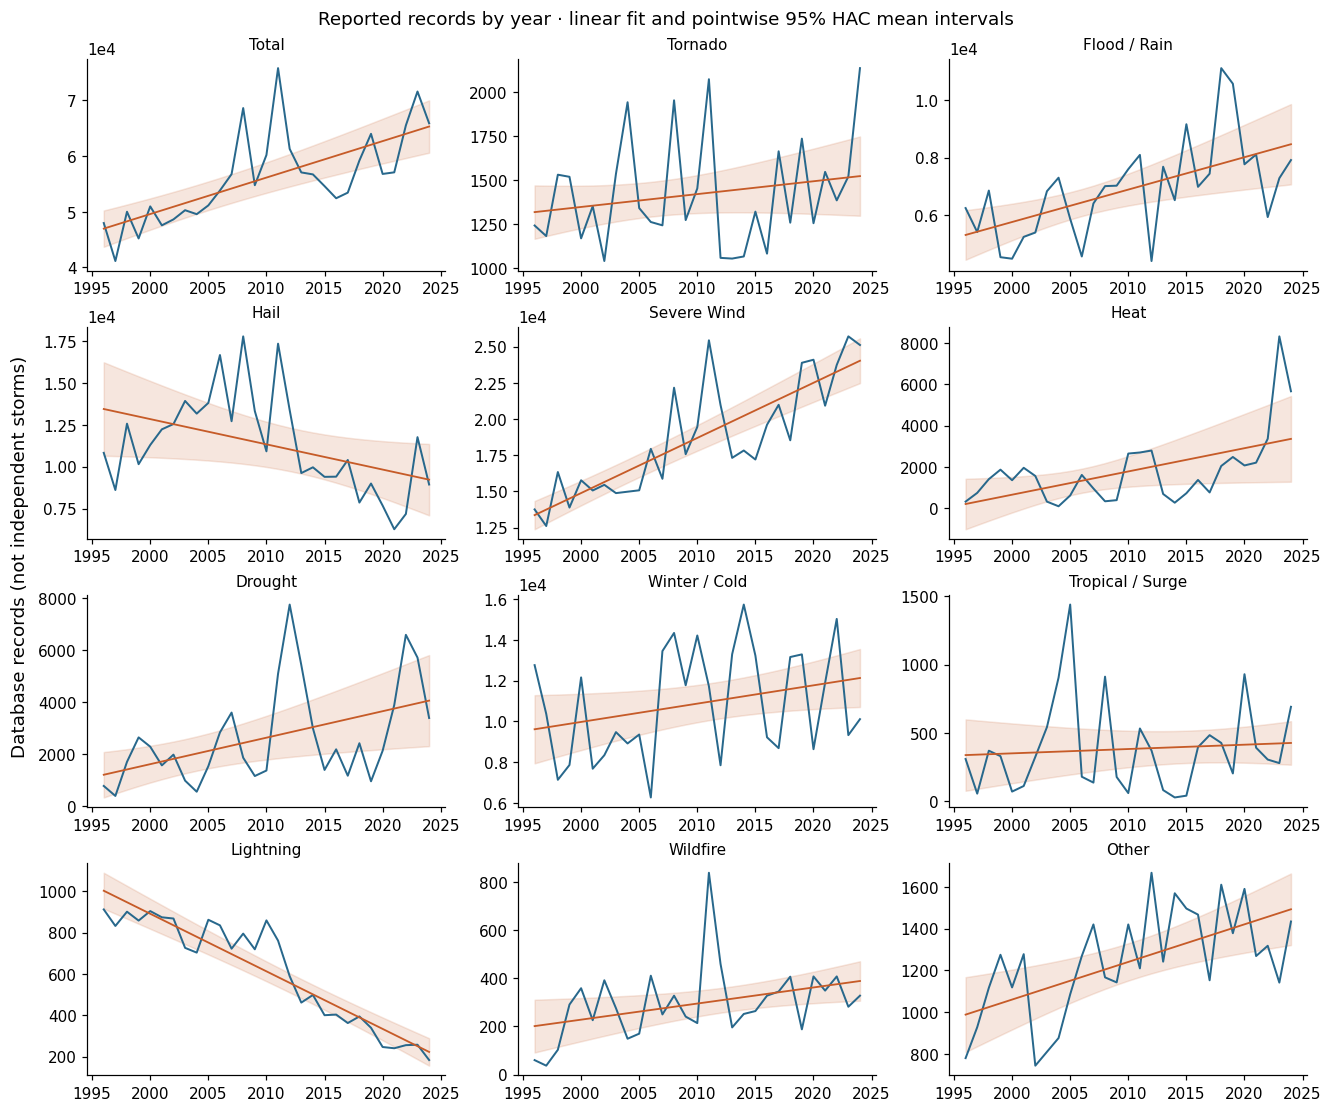

,estimate,ci_low,ci_high,p_hac,p_holm_10_hazards
outcome,,,,,
Tornado,7.311,-4.044,18.666,0.198,0.395
Flood / Rain,112.462,39.885,185.039,0.004,0.029
Hail,-150.458,-299.002,-1.914,0.047,0.221
Severe Wind,380.940,313.797,448.083,0.000,0.000
Heat,112.618,3.150,222.085,0.044,0.221
Drought,102.152,23.411,180.893,0.013,0.091
Winter / Cold,89.923,0.274,179.572,0.049,0.221
Tropical / Surge,3.175,-8.984,15.335,0.596,0.596
Lightning,-27.870,-32.203,-23.538,0.000,0.000


In [4]:
display(figures[1])
display(result['trends'].set_index('outcome'))

As a counting-unit sensitivity check, records sharing **state, hazard group and start date** are collapsed. This reduces repeated county/zone reporting within the same state-day, but it can also combine distinct storms and does not identify a physical storm. Long-duration events are assigned to their recorded start date. EPISODE_ID is not assumed to represent one nationally consistent, independent storm.

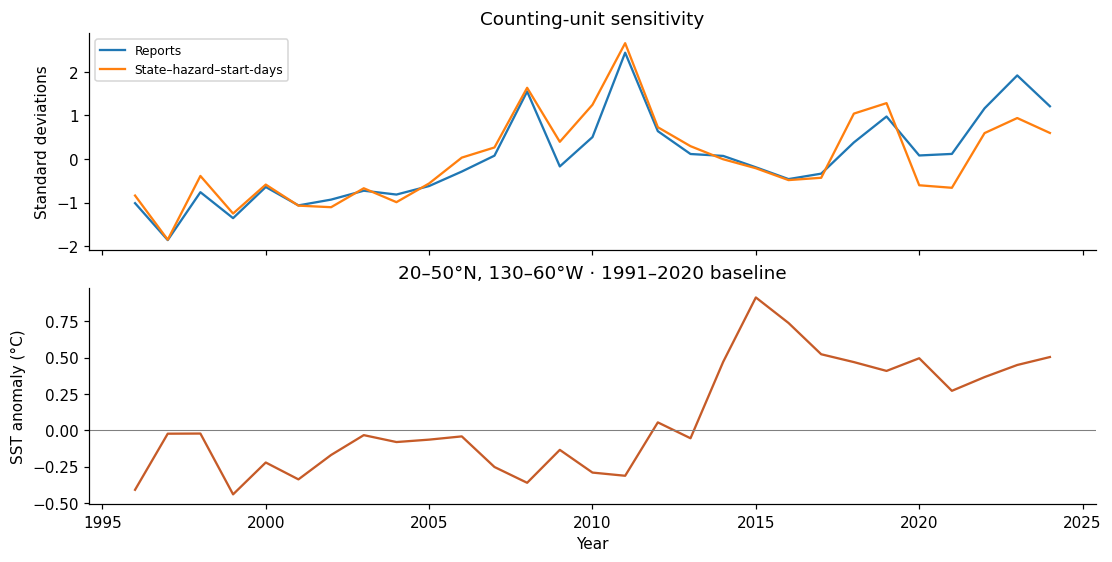

In [5]:
display(figures[4])

## 4. Seasonality: years as the sampling unit

For each year, the 12 monthly counts are divided by that year's total. Early and late profiles are the arithmetic means of these annual share vectors, so each year has equal weight. The difference is late minus early, in percentage points.

Uncertainty uses **4,000 moving-block bootstrap resamples of whole annual vectors within each period**, with blocks of two consecutive years and random seed 42. Each resample is truncated to the original period length. Three-year blocks provide a sensitivity check. The 95% percentile intervals are **pointwise**, not a simultaneous test of all 12 months. They assume approximate stability within each period and only short-range dependence; the short series limits precision.

This replaces a pooled-record chi-square test, whose independence assumption is unsuitable for clustered weather reports. Monthly differences can also arise from changes in the mixture of hazards. They do not establish earlier onset or a longer physical weather season. Drought and other long-duration hazards are represented by record start month, not every month affected.

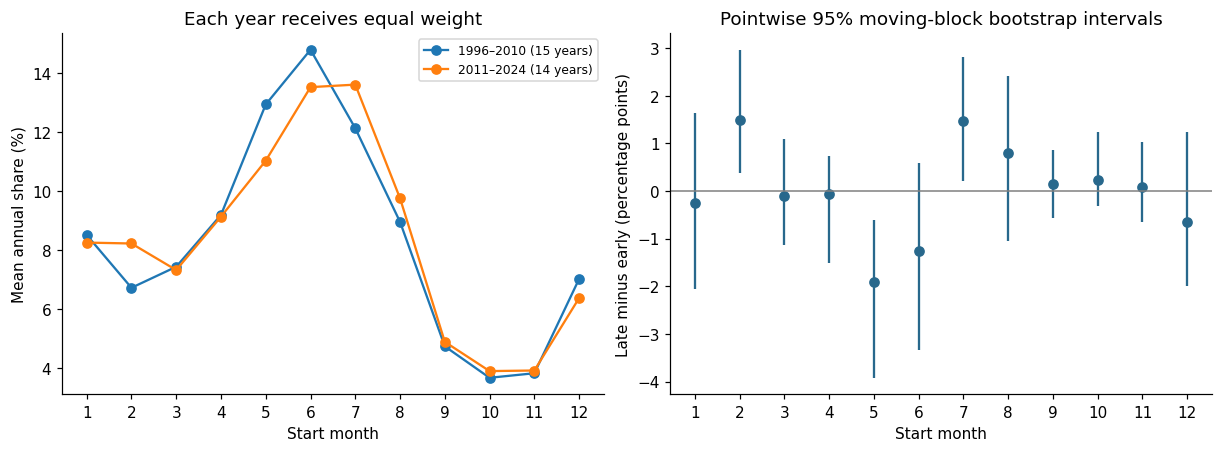

,month,block_years,early_share_pct,late_share_pct,difference_pp,pointwise_ci_low,pointwise_ci_high
0,1,2,8.518,8.260,-0.258,-2.058,1.641
1,2,2,6.730,8.229,1.500,0.384,2.966
2,3,2,7.441,7.330,-0.111,-1.126,1.093
3,4,2,9.197,9.138,-0.059,-1.504,0.725
4,5,2,12.937,11.034,-1.903,-3.922,-0.600
5,6,2,14.790,13.523,-1.266,-3.329,0.587
6,7,2,12.131,13.608,1.477,0.214,2.818
7,8,2,8.960,9.758,0.798,-1.060,2.415
8,9,2,4.747,4.899,0.151,-0.563,0.852
9,10,2,3.682,3.909,0.227,-0.311,1.233


In [6]:
display(figures[2])
display(result['seasonal_differences'].round(3))

Hazard-specific seasonal profiles are also exported. They are descriptive, with the number of observed years reported for each group and period. This helps distinguish aggregate composition changes from within-hazard timing changes; it does not fully adjust for changes in reporting.

## 5. Geography

The bars compare the 15 states with the largest raw totals, using both counting units. They measure where records are concentrated. They are **not a ranking of risk**: state area, population, assets, hazard mix and reporting practices differ. A hazard-risk comparison would require a defined exposure denominator and a hazard-specific design.

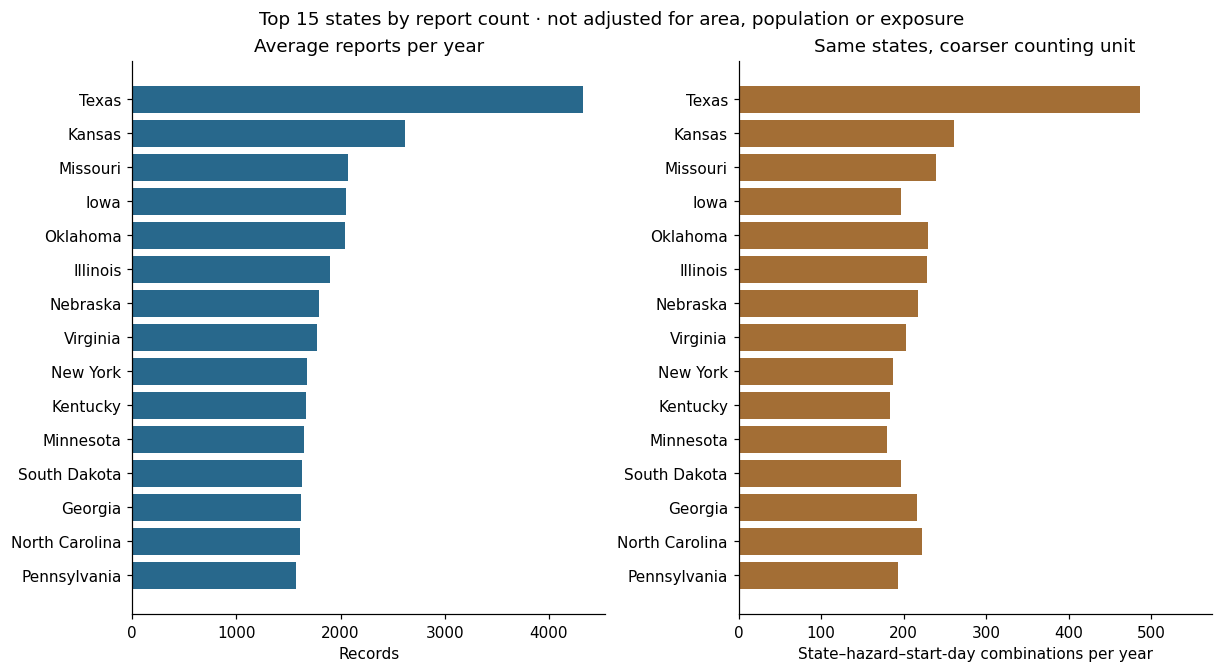

In [7]:
display(figures[3])

## 6. SST association after accounting for shared trends

The main model is $N_t = \alpha + \beta\,SST_t + \gamma(t-\bar t) + \epsilon_t$. The SST coefficient describes the association conditional on a **linear year term**. Its units are reports per °C. Uncertainty uses the same two-lag HAC specification as above.

Raw Pearson correlations are shown alongside correlations of linearly detrended residuals and first differences. These correlations are descriptive; conventional independent-year Pearson p-values are not used. Detrending both series gives the same SST slope as the joint regression with year, but removing a time trend is not a causal identification strategy.

The SST table applies Holm correction to the ten named hazard coefficients as a separate exploratory testing family. Total, Other and the coarser counting-unit sensitivity are not included in that correction. None of these adjustments controls omitted mechanisms such as ENSO, reporting changes or exposure.

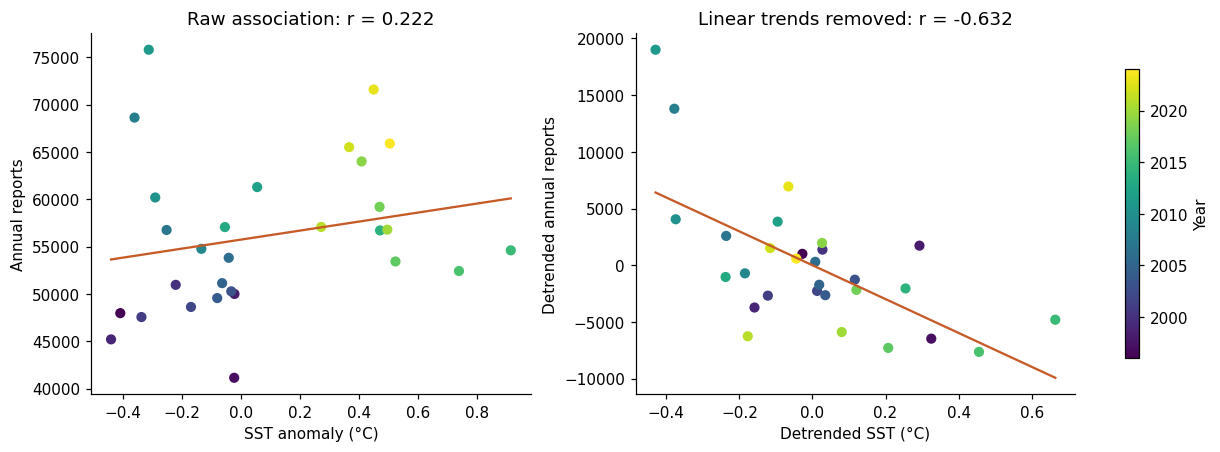

,n_years,raw_r,detrended_r,first_difference_r,estimate,ci_low,ci_high,p_hac,residual_lag1_r,p_holm_10_hazards
outcome,,,,,,,,,,
Tornado,29,-0.056,-0.323,-0.327,-396.868,-644.998,-148.738,0.003,-0.108,0.029
Flood / Rain,29,0.519,0.148,-0.125,803.097,-659.334,"2,265.529",0.269,0.087,0.808
Hail,29,-0.571,-0.406,-0.031,"-4,307.889","-8,159.074",-456.703,0.030,0.233,0.179
Severe Wind,29,0.454,-0.477,-0.114,"-4,173.410","-6,857.452","-1,489.368",0.004,-0.192,0.033
Heat,29,0.277,-0.254,-0.029,"-1,492.147","-3,440.057",455.763,0.127,0.500,0.558
Drought,29,0.105,-0.416,-0.184,"-2,823.652","-4,959.870",-687.433,0.012,0.454,0.092
Winter / Cold,29,0.092,-0.201,-0.225,"-2,057.117","-6,416.608","2,302.374",0.341,0.106,0.808
Tropical / Surge,29,-0.008,-0.106,-0.108,-142.244,-472.233,187.746,0.384,0.163,0.808
Lightning,29,-0.839,-0.579,-0.180,-207.276,-377.320,-37.231,0.019,0.300,0.132


,check,estimate,ci_low,ci_high,p_hac
0,HAC lag 1,"-14,932.791","-24,641.061","-5,224.520",0.004
1,HAC lag 2,"-14,932.791","-23,907.144","-5,958.437",0.002
2,HAC lag 3,"-14,932.791","-24,175.860","-5,689.722",0.003
3,"First differences, HAC lag 2","-8,636.213","-22,232.264","4,959.838",0.203
4,"Quadratic time trend, HAC lag 2","-14,568.497","-22,896.495","-6,240.499",0.001


Leave-one-year-out SST slopes for total reports range from **-17,817** to **-11,224 reports/°C**. These are coefficient sensitivity checks, not additional hypothesis tests.

In [8]:
display(figures[5])
display(result['sst_associations'].set_index('outcome'))
display(result['sst_sensitivity'])
loo = result['leave_one_year_out']
display(Markdown(f"Leave-one-year-out SST slopes for total reports range from **{loo.sst_slope.min():,.0f}** to **{loo.sst_slope.max():,.0f} reports/°C**. These are coefficient sensitivity checks, not additional hypothesis tests."))

HAC lags 1–3 assess dependence on the covariance setting. A quadratic time term checks one alternative trend shape. First differences provide a separate check against shared smooth drift, while amplifying measurement noise. Leave-one-year-out coefficients check whether one year drives the slope; confidence intervals from that exercise are not interpreted because removing a year creates irregular time gaps. Residual lag-one correlations are exported as a limited diagnostic, not a guarantee of independent errors.

A remaining association could reflect physical mechanisms, reporting changes or omitted variables. A weak or imprecise association would not show that climate change has no effect on hazards. The broad index, heterogeneous outcome and short series limit either interpretation.

## 7. Reported damage and missingness

Property and crop estimates are converted to 2024 dollars using annual, non-seasonally-adjusted CPI-U. A record contributes the sum of its **available components**; when both are missing it remains missing. A second series includes only records with both components known. Explicit reported zeros are included. Missingness rates are shown by year.

The period comparison uses **mean annual damage**, with each period's number of years displayed. This avoids comparing totals from a four-year period with totals from a ten-year period. Annual medians and the complete-case sensitivity are also exported. These are descriptive comparisons, with no inferred period treatment effect.

Inflation adjustment does not normalize population, wealth, exposed assets, vulnerability or reporting. The result is an aggregation of available reported direct property/crop estimates, not comprehensive economic loss, an unbiased lower bound, or an estimate of damage caused by warming. The visible break in missingness around 2007 is an additional reason to avoid interpreting period differences as changes in true loss. Large source estimates can dominate the totals; the largest records are displayed for audit and are not automatically winsorized or replaced.

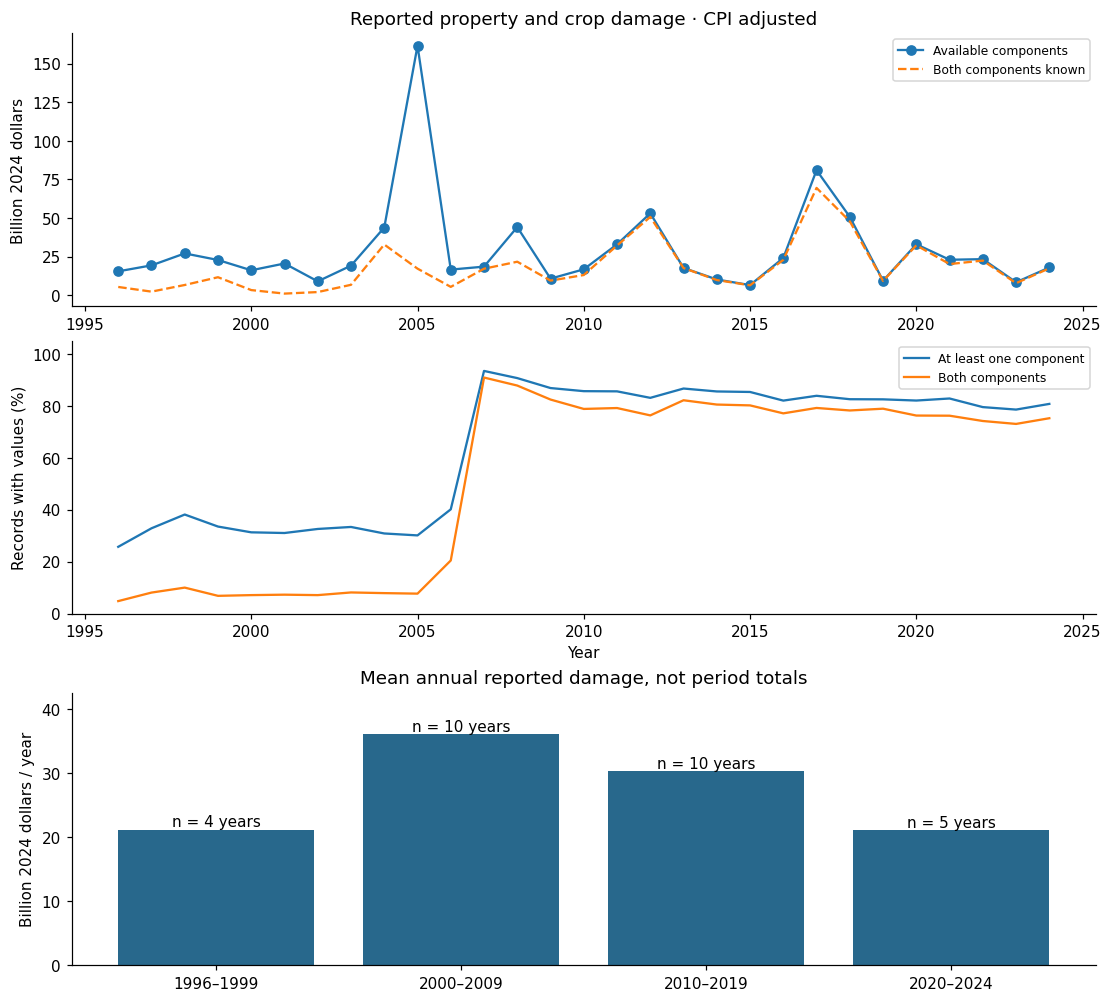

,period,years,mean_annual_available_2024,median_annual_available_2024,mean_annual_complete_case_2024
0,1996–1999,4,"21,169,527,334.447","21,072,372,815.721","6,482,703,596.619"
1,2000–2009,10,"36,019,698,674.898","18,822,665,152.902","11,689,022,728.542"
2,2010–2019,10,"30,239,333,987.181","20,899,990,023.016","27,930,748,899.046"
3,2020–2024,5,"21,133,354,109.274","22,964,323,918.186","20,026,381,483.975"


,EVENT_ID,EPISODE_ID,date,STATE,EVENT_TYPE,DAMAGE_PROPERTY,DAMAGE_CROPS,damage_2024
483196,5475650,"1,198,567.000",2005-08-29,LOUISIANA,Storm Surge/Tide,17.9B,<NA>,"28,750,809,523.810"
1273087,788675,"131,864.000",2018-11-08,CALIFORNIA,Wildfire,17.00B,0.00K,"21,236,815,381.491"
496464,5477628,"1,199,954.000",2005-10-24,FLORIDA,Hurricane (Typhoon),10B,<NA>,"16,061,904,761.905"
1238175,720861,"119,753.000",2017-08-26,TEXAS,Flash Flood,10.00B,100.00K,"12,797,492,529.781"
1237560,720871,"119,753.000",2017-08-26,TEXAS,Flash Flood,10.00B,10.00K,"12,797,377,353.500"
918998,416942,"68,471.000",2012-10-29,NEW JERSEY,Coastal Flood,7.50B,0.00K,"10,247,077,449.759"
1237394,720852,"119,753.000",2017-08-26,TEXAS,Flash Flood,8.00B,50.00K,"10,237,955,631.731"
483804,5475657,"1,198,568.000",2005-08-29,MISSISSIPPI,Storm Surge/Tide,5.63B,<NA>,"9,042,852,380.952"
1237556,728349,"119,753.000",2017-08-27,TEXAS,Flash Flood,7.00B,10.00K,"8,958,167,986.660"
272819,5256253,"1,118,293.000",2001-06-05,TEXAS,Tropical Storm,5.03B,<NA>,"8,909,405,251.270"


In [9]:
display(figures[6])
display(result['damage_periods'])
display(result['largest_damage_records'])

## 8. What the revised analysis supports

The following statements are generated from the current run so that the narrative cannot retain obsolete numbers after a data update. A confidence interval containing zero indicates uncertainty under this model, not proof of no relationship. An interval excluding zero still does not establish a physical or causal mechanism.

In [10]:
t = result['trends'].set_index('outcome').loc['Total']
a = result['sst_associations'].set_index('outcome').loc['Total']
c = result['sst_associations'].set_index('outcome').loc['state_hazard_start_days']
d = result['annual_damage']
relation = 'includes zero' if a.ci_low <= 0 <= a.ci_high else 'excludes zero'
display(Markdown(f'''
- **Coverage:** {result['quality']['conus_records']:,} records over 29 years, using the stated CONUS scope.
- **Report-count trend:** {t.estimate:,.0f} records/year; 95% HAC interval [{t.ci_low:,.0f}, {t.ci_high:,.0f}]. This is a trend in reporting counts.
- **SST association:** raw r = {a.raw_r:.3f}; detrended r = {a.detrended_r:.3f}; first-difference r = {a.first_difference_r:.3f}.
- **Year-adjusted SST slope:** {a.estimate:,.0f} reports/°C; 95% HAC interval [{a.ci_low:,.0f}, {a.ci_high:,.0f}], which {relation}.
- **Coarser-unit sensitivity:** detrended r = {c.detrended_r:.3f}. Counting choices are part of the uncertainty, not a solved reporting-bias problem.
- **Damage coverage:** the annual share with both components known ranges from {d.both_components_known_share.min():.1%} to {d.both_components_known_share.max():.1%}. Missingness limits comparisons across years.
'''))


- **Coverage:** 1,627,967 records over 29 years, using the stated CONUS scope.
- **Report-count trend:** 655 records/year; 95% HAC interval [443, 867]. This is a trend in reporting counts.
- **SST association:** raw r = 0.222; detrended r = -0.632; first-difference r = -0.275.
- **Year-adjusted SST slope:** -14,933 reports/°C; 95% HAC interval [-23,907, -5,958], which excludes zero.
- **Coarser-unit sensitivity:** detrended r = -0.569. Counting choices are part of the uncertainty, not a solved reporting-bias problem.
- **Damage coverage:** the annual share with both components known ranges from 4.8% to 90.9%. Missingness limits comparisons across years.


## 9. Limits and a narrower research extension

This project demonstrates data ingestion and auditing, Pandas aggregation, Xarray climate processing, explicit uncertainty calculations and reproducible scientific plotting. Its strongest claim is a transparent description of these records. It is not yet a causal climate-attribution study.

A useful next project would choose **one hazard, one region and one proposed mechanism**. It would validate the reporting history, define an exposure denominator, select a physically relevant climate indicator and specify confounders before testing. For example, a heat-focused design should first establish how heat reports relate to independently measured temperature exceedances. A count-model extension could then evaluate overdispersion, exposure offsets and dependence; changing the regression family alone would not solve measurement or identification problems.

For feedback, the central questions are whether the counting unit matches the scientific question, which hazard offers defensible measurement, and what additional data could support stronger inference.

## Sources

- [NOAA Storm Events bulk files](https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/) and [field definitions](https://www.ncei.noaa.gov/pub/data/swdi/stormevents/csvfiles/Storm-Data-Bulk-csv-Format.pdf).
- [NOAA ERSSTv5 documentation](https://psl.noaa.gov/data/gridded/data.noaa.ersst.v5.html).
- [BLS historical annual CPI-U table, December 2024 release](https://www.bls.gov/cpi/tables/supplemental-files/historical-cpi-u-202412.pdf).
- [Statsmodels robust covariance documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLSResults.get_robustcov_results.html).